In [1]:
import os
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("../reports/figures", exist_ok=True)
sns.set_theme(style="whitegrid")

conn = sqlite3.connect("../data/lending_club.db")
df = pd.read_sql_query("SELECT * FROM loans_clean", conn)
df["issue_date"] = pd.to_datetime(df["issue_date"])
print(df.shape)
df.head()

Matplotlib is building the font cache; this may take a moment.


(733283, 30)


,id,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_length,home_ownership,annual_inc,...,open_acc,pub_rec,revol_bal,revol_util,total_acc,application_type,issue_date,is_default,term_months,issue_year
0,68407277,3600.0,36 months,13.99,123.03,C,C4,10+ years,MORTGAGE,55000.0,...,7.0,0.0,2765.0,29.7,13.0,Individual,2015-12-01,0,36,2015
1,68355089,24700.0,36 months,11.99,820.28,C,C1,10+ years,MORTGAGE,65000.0,...,22.0,0.0,21470.0,19.2,38.0,Individual,2015-12-01,0,36,2015
2,68341763,20000.0,60 months,10.78,432.66,B,B4,10+ years,MORTGAGE,63000.0,...,6.0,0.0,7869.0,56.2,18.0,Joint App,2015-12-01,0,60,2015
3,68476807,10400.0,60 months,22.45,289.91,F,F1,3 years,MORTGAGE,104433.0,...,12.0,0.0,21929.0,64.5,35.0,Individual,2015-12-01,0,60,2015
4,68426831,11950.0,36 months,13.44,405.18,C,C3,4 years,RENT,34000.0,...,5.0,0.0,8822.0,68.4,6.0,Individual,2015-12-01,0,36,2015


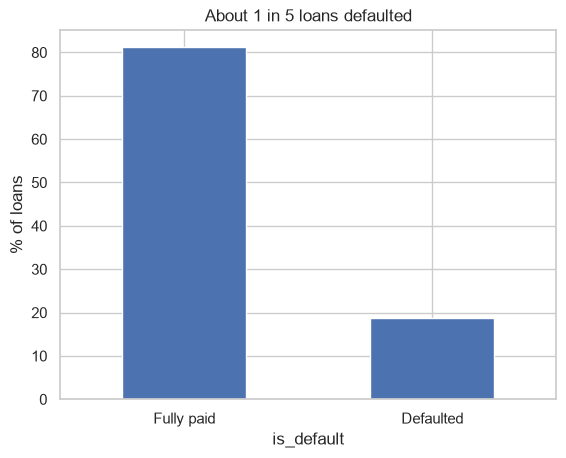

In [2]:
rates = df["is_default"].value_counts(normalize=True).mul(100)
ax = rates.rename({0: "Fully paid", 1: "Defaulted"}).plot(kind="bar", rot=0)
ax.set_title("About 1 in 5 loans defaulted")
ax.set_ylabel("% of loans")
plt.savefig("../reports/figures/01_target_balance.png", dpi=150, bbox_inches="tight")
plt.show()

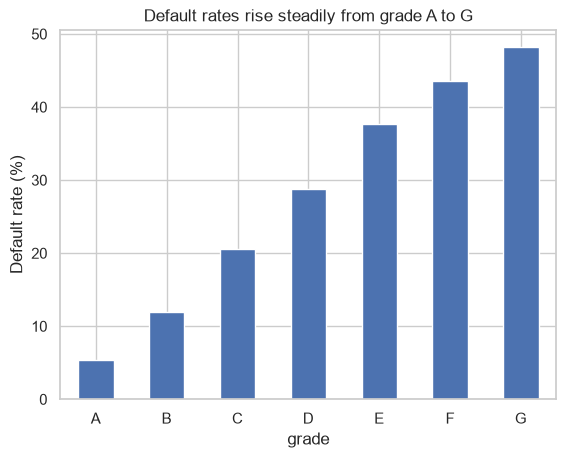

In [3]:
by_grade = df.groupby("grade")["is_default"].mean().mul(100)
ax = by_grade.plot(kind="bar", rot=0)
ax.set_title("Default rates rise steadily from grade A to G")
ax.set_ylabel("Default rate (%)")
plt.savefig("../reports/figures/02_default_by_grade.png", dpi=150, bbox_inches="tight")
plt.show()

/var/folders/z1/8cgdfn9s2n5d27z1p_36cz_r0000gn/T/ipykernel_8829/816603854.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["Fully paid", "Defaulted"])


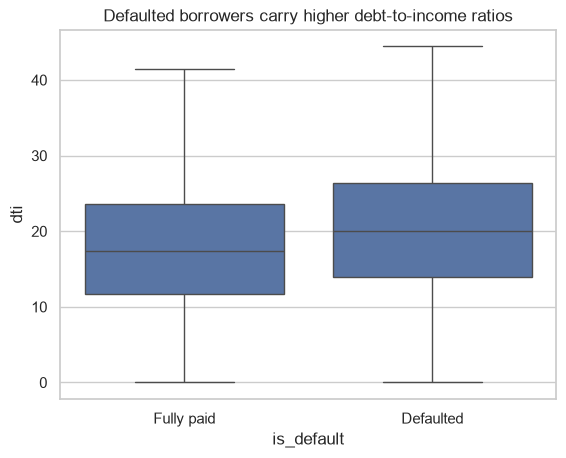

In [4]:
ax = sns.boxplot(data=df, x="is_default", y="dti", showfliers=False)
ax.set_xticklabels(["Fully paid", "Defaulted"])
ax.set_title("Defaulted borrowers carry higher debt-to-income ratios")
plt.savefig("../reports/figures/03_dti_by_outcome.png", dpi=150, bbox_inches="tight")
plt.show()

/var/folders/z1/8cgdfn9s2n5d27z1p_36cz_r0000gn/T/ipykernel_8829/9558693.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["Fully paid", "Defaulted"])


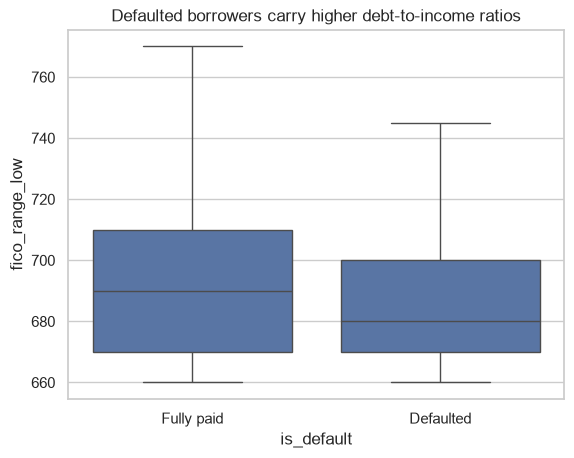

In [5]:
ax = sns.boxplot(data=df, x="is_default", y="fico_range_low", showfliers=False)
ax.set_xticklabels(["Fully paid", "Defaulted"])
ax.set_title("Defaulted borrowers carry higher debt-to-income ratios")
plt.savefig("../reports/figures/03_fico_by_outcome.png", dpi=150, bbox_inches="tight")
plt.show()

/var/folders/z1/8cgdfn9s2n5d27z1p_36cz_r0000gn/T/ipykernel_8829/3140396165.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["Fully paid", "Defaulted"])


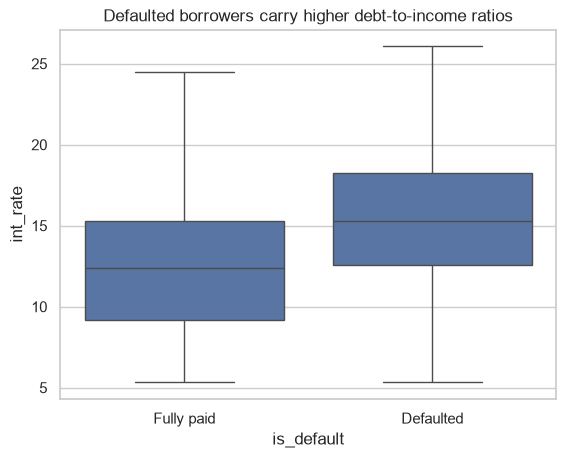

In [6]:
ax = sns.boxplot(data=df, x="is_default", y="int_rate", showfliers=False)
ax.set_xticklabels(["Fully paid", "Defaulted"])
ax.set_title("Defaulted borrowers carry higher debt-to-income ratios")
plt.savefig("../reports/figures/03_int_rate_by_outcome.png", dpi=150, bbox_inches="tight")
plt.show()

/var/folders/z1/8cgdfn9s2n5d27z1p_36cz_r0000gn/T/ipykernel_8829/2885883887.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["Fully paid", "Defaulted"])


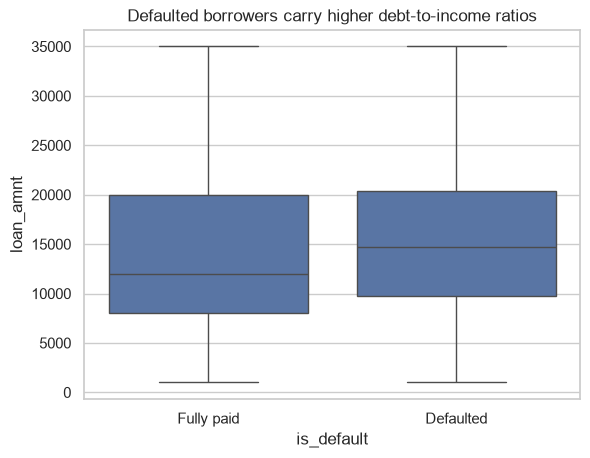

In [7]:
ax = sns.boxplot(data=df, x="is_default", y="loan_amnt", showfliers=False)
ax.set_xticklabels(["Fully paid", "Defaulted"])
ax.set_title("Defaulted borrowers carry higher debt-to-income ratios")
plt.savefig("../reports/figures/03_loan_amnt_by_outcome.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
for col in ["term_months", "purpose", "home_ownership"]:
    print(df.groupby(col)["is_default"].agg(["count", "mean"]).sort_values("mean", ascending=False), "\n")

              count      mean
term_months                  
60           187397  0.326334
36           545886  0.140707 

                     count      mean
purpose                             
small_business        6612  0.275106
renewable_energy       384  0.223958
moving                4240  0.223585
house                 2730  0.216850
debt_consolidation  437660  0.200217
medical               6838  0.200058
other                33757  0.199603
major_purchase       12713  0.177220
vacation              3917  0.174368
home_improvement     42390  0.170630
credit_card         175416  0.157614
wedding                607  0.149918
car                   6018  0.145896
educational              1  0.000000 

                 count      mean
home_ownership                  
RENT            292448  0.215549
OWN              74132  0.192913
MORTGAGE        366700  0.165329
ANY                  3  0.000000 



In [9]:
df.groupby("issue_year")["is_default"].mean().mul(100)

issue_year
2013    15.597828
2014    18.450297
2015    20.185925
Name: is_default, dtype: float64

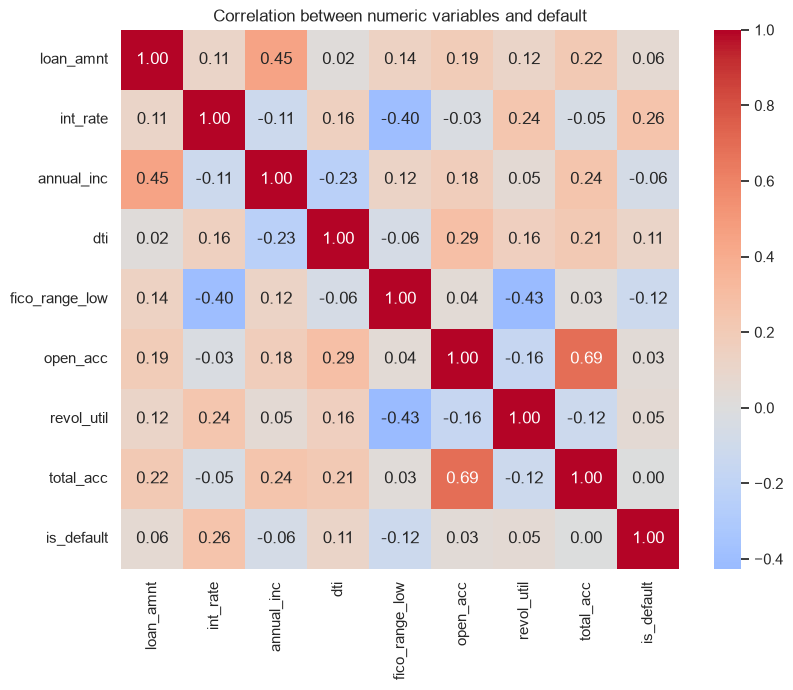

In [10]:
num_cols = ["loan_amnt", "int_rate", "annual_inc", "dti", "fico_range_low",
            "open_acc", "revol_util", "total_acc", "is_default"]
corr = df[num_cols].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between numeric variables and default")
plt.savefig("../reports/figures/04_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
# Employment length as a number, plus a flag for missing
emp_map = {"< 1 year": 0, "1 year": 1, "2 years": 2, "3 years": 3, "4 years": 4,
           "5 years": 5, "6 years": 6, "7 years": 7, "8 years": 8, "9 years": 9,
           "10+ years": 10}
df["emp_length_yrs"] = df["emp_length"].map(emp_map)
df["emp_length_missing"] = df["emp_length"].isna().astype(int)

# Cap revolving utilization at 100
df["revol_util"] = df["revol_util"].clip(upper=100)

# Average FICO score
df["fico_avg"] = (df["fico_range_low"] + df["fico_range_high"]) / 2

# Length of credit history in years at time of loan
df["earliest_cr_line"] = pd.to_datetime(df["earliest_cr_line"], format="%b-%Y", errors="coerce")
df["credit_history_years"] = (df["issue_date"] - df["earliest_cr_line"]).dt.days / 365.25

# Affordability ratios
df["loan_to_income"] = df["loan_amnt"] / df["annual_inc"]
df["payment_to_income"] = (df["installment"] * 12) / df["annual_inc"]
df["log_income"] = np.log1p(df["annual_inc"])

df[["emp_length_yrs", "fico_avg", "credit_history_years",
    "loan_to_income", "payment_to_income"]].describe()

,emp_length_yrs,fico_avg,credit_history_years,loan_to_income,payment_to_income
count,693723.000000,733283.000000,733283.000000,733283.000000,733283.000000
mean,6.057635,695.467929,16.489859,0.219331,0.080338
std,3.668353,29.771406,7.483287,0.110488,0.040602
min,0.000000,662.000000,3.000684,0.001600,0.000592
25%,3.000000,672.000000,11.414100,0.133333,0.049256
50%,7.000000,687.000000,14.997947,0.205882,0.074940
75%,10.000000,712.000000,20.251882,0.298507,0.106828
max,10.000000,847.500000,71.000684,1.782060,0.672169


In [17]:
df["purpose"] = df["purpose"].replace({"educational": "other"})
df["home_ownership"] = df["home_ownership"].replace({"ANY": "OTHER"})

In [18]:
numeric_applicant = ["loan_amnt", "term_months", "log_income", "dti", "fico_avg",
                     "delinq_2yrs", "open_acc", "pub_rec", "revol_bal", "revol_util",
                     "total_acc", "emp_length_yrs", "emp_length_missing",
                     "credit_history_years", "loan_to_income", "payment_to_income"]

categorical_applicant = ["home_ownership", "verification_status", "purpose",
                         "application_type"]

lc_assigned = ["grade", "int_rate"]   # used only in Model B

In [19]:
all_cols = numeric_applicant + categorical_applicant + lc_assigned
missing = [c for c in all_cols if c not in df.columns]
print("Missing columns:", missing)

Missing columns: []


In [20]:
from sklearn.model_selection import train_test_split

features = numeric_applicant + categorical_applicant + lc_assigned
X = df[features]
y = df["is_default"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(586626, 22) (146657, 22)
0.18814542826264094 0.18814649147330165


In [21]:
os.makedirs("../data/processed", exist_ok=True)
X_train.assign(is_default=y_train).to_csv("../data/processed/train.csv", index=False)
X_test.assign(is_default=y_test).to_csv("../data/processed/test.csv", index=False)

In [22]:
# Share of 60-month loans by year
df.groupby("issue_year")["term_months"].apply(lambda s: (s == 60).mean() * 100)

issue_year
2013    25.505980
2014    27.134372
2015    24.635874
Name: term_months, dtype: float64

In [23]:
# Default rate by year, 36-month loans only
df[df["term_months"] == 36].groupby("issue_year")["is_default"].mean() * 100

issue_year
2013    12.327580
2014    13.726660
2015    14.886969
Name: is_default, dtype: float64